In [1]:
import sys 
sys.path.append(".")
sys.path.append("..")
import torch
from typing import List

from utils import vis_utils
from utils.ptp_utils import AttentionStore
from pipeline_frap import FrapPipeline
from config_frap import RunConfig
from run_frap import run_on_prompt
        
%load_ext autoreload 
%autoreload 2

# Pipeline Wrapper

In [2]:
def run_and_display(model,
                    prompts: List[str],
                    controller: AttentionStore,
                    indices_to_alter: List[int],
                    generator: torch.Generator,
                    run_standard_sd: bool = False,
                    display_output: bool = False):
    
    config = RunConfig(prompt=prompts,
                       run_standard_sd=run_standard_sd)
    
    image = run_on_prompt(model=model,
                          prompt=prompts,
                          controller=controller,
                          token_indices=[indices_to_alter],
                          seed=generator,
                          config=config)
                        
    if display_output:
        display(image[0])
    return image


# Load Model Weights (may take a few minutes)

In [3]:
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
dtype = torch.float16

stable = FrapPipeline.from_pretrained("CompVis/stable-diffusion-v1-5", torch_dtype=dtype).to(device)
tokenizer = stable.tokenizer

## Text-to Image Generation with FRAP


Seed: 10
A black cat sitting on top of a green bench in a field
subtrees [[black, sitting, cat], [green, bench]]
Final pairs collected: [[green, bench], [black, sitting, cat]]


  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

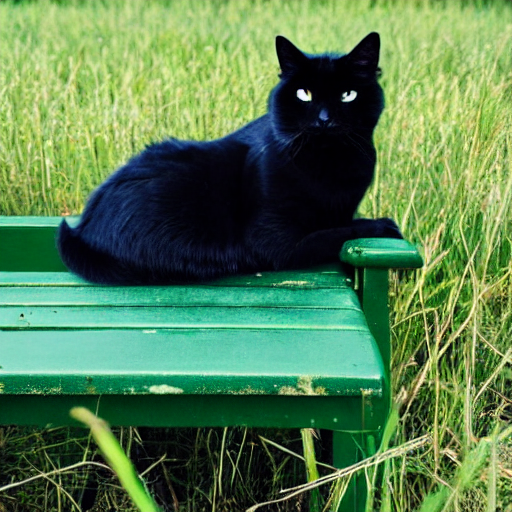

Seed: 48
A black cat sitting on top of a green bench in a field
subtrees [[black, sitting, cat], [green, bench]]
Final pairs collected: [[green, bench], [black, sitting, cat]]


  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

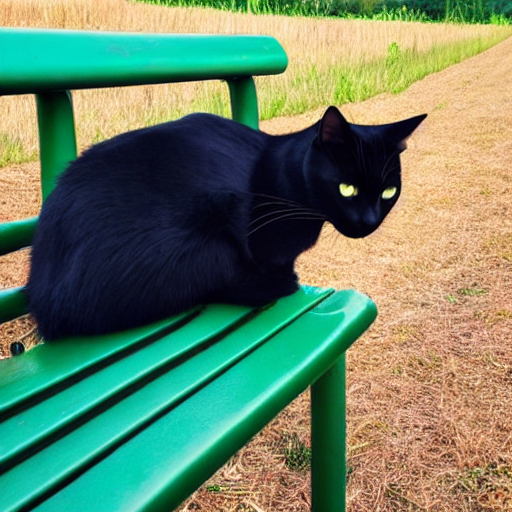

In [7]:
prompt = "A black cat sitting on top of a green bench in a field"
seeds = [10, 48]
token_indices = list(range(1, len(stable.tokenizer(prompt)['input_ids'])-1))

for seed in seeds:
    print("Seed:",seed)
    g = torch.Generator('cuda').manual_seed(seed)
    controller = AttentionStore()
    
    image = run_and_display(model=stable,
                            prompts=[prompt],
                            controller=controller,
                            indices_to_alter=token_indices,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True)

    # vis_utils.show_cross_attention(attention_store=controller,
    #                                 prompt=prompt,
    #                                 tokenizer=tokenizer,
    #                                 res=16,
    #                                 from_where=("up", "down", "mid"),
    #                                 indices_to_alter=token_indices,
    #                                 orig_image=image[0])
